In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import models, transforms
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

Model Definition

In [ ]:
from albumentations.pytorch import ToTensorV2
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm


# -------------------------------------------------------
# Attention Gate
# -------------------------------------------------------

class AttentionBlock(nn.Module):
    def __init__(self, x_channels, g_channels, inter_channels):
        super().__init__()

        self.theta = nn.Conv2d(x_channels, inter_channels, 1)
        self.phi   = nn.Conv2d(g_channels, inter_channels, 1)
        self.psi   = nn.Conv2d(inter_channels, 1, 1)

        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, g):

        theta = self.theta(x)
        phi   = self.phi(g)

        attn = self.relu(theta + phi)
        attn = self.sigmoid(self.psi(attn))

        return x * attn


# -------------------------------------------------------
# Conv Block 
# -------------------------------------------------------

class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_c, out_c,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.norm1 = nn.GroupNorm(32, out_c)

        self.conv2 = nn.Conv2d(
            out_c, out_c,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.norm2 = nn.GroupNorm(32, out_c)

        self.conv3 = nn.Conv2d(
            out_c, out_c,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.norm3 = nn.GroupNorm(32, out_c)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout2d(0.2)

        # Match channels for residual connection
        if in_c != out_c:
            self.residual = nn.Sequential(
                nn.Conv2d(
                    in_c,
                    out_c,
                    kernel_size=1,
                    bias=False
                ),
                nn.GroupNorm(32, out_c)
            )
        else:
            self.residual = nn.Identity()

    def forward(self, x):

        identity = self.residual(x)

        out = self.relu(self.norm1(self.conv1(x)))
        out = self.relu(self.norm2(self.conv2(out)))
        out = self.norm3(self.conv3(out))

        out = out + identity
        out = self.relu(out)

        out = self.dropout(out)

        return out


# -------------------------------------------------------
# Decoder Block
# -------------------------------------------------------

class DecoderBlock(nn.Module):

    def __init__(self,
                 in_channels,
                 skip_channels,
                 out_channels):

        super().__init__()

        self.att = AttentionBlock(
            x_channels=skip_channels,
            g_channels=in_channels,
            inter_channels=skip_channels,
        )

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        skip = self.att(skip, x)

        x = torch.cat([x, skip], dim=1)

        return self.conv(x)


# -------------------------------------------------------
# Refinement Block
# -------------------------------------------------------

class RefinementBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = ConvBlock(
            in_channels,
            out_channels
        )

    def forward(self, x):

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        return self.conv(x)


# -------------------------------------------------------
# ConvNeXt Attention U-Net
# -------------------------------------------------------

class ConvNeXtUNet(nn.Module):

    def __init__(self):

        super().__init__()

        # ---------------- Encoder ----------------

        self.encoder = timm.create_model(
            "convnext_tiny",
            pretrained=True,
            features_only=True,
            out_indices=(0,1,2,3)
        )

        # channels
        # e1 = 96
        # e2 = 192
        # e3 = 384
        # e4 = 768

        # ---------------- Decoder ----------------

        self.dec4 = DecoderBlock(
            in_channels=768,
            skip_channels=384,
            out_channels=384
        )

        self.dec3 = DecoderBlock(
            in_channels=384,
            skip_channels=192,
            out_channels=192
        )

        self.dec2 = DecoderBlock(
            in_channels=192,
            skip_channels=96,
            out_channels=96
        )

        # no skip connections

        self.ref1 = RefinementBlock(
            96,
            64
        )

        self.ref0 = RefinementBlock(
            64,
            64
        )

        self.final = nn.Conv2d(
            64,
            1,
            kernel_size=1
        )

        self.final.bias.data.fill_(-2.0)

    def forward(self, x):

        # ---------------- Encoder ----------------

        e1, e2, e3, e4 = self.encoder(x)

        # e1 : 96 x128
        # e2 : 192 x64
        # e3 : 384 x32
        # e4 : 768 x16

        # ---------------- Decoder ----------------

        d4 = self.dec4(e4, e3)   # 384 x32

        d3 = self.dec3(d4, e2)   # 192 x64

        d2 = self.dec2(d3, e1)   # 96 x128

        d1 = self.ref1(d2)       # 64 x256

        d0 = self.ref0(d1)       # 64 x512

        out = self.final(d0)

        return out

Load model

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = ConvNeXtUNet().to(device)
model.load_state_dict(torch.load("convnext_unet_residual.pth", map_location=device))
model.eval()

import albumentations as A
from albumentations.pytorch import ToTensorV2

infer_transform = A.Compose([
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2(),
])


/tmp/ipykernel_940675/626638169.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("vgg16_unet_best.pth", map_location=device))
/home/prati

Sliding window inference

In [ ]:
import numpy as np
import torch
import cv2


def get_gaussian_weight(patch_size, sigma_scale=1/8):
    """
    Create a 2D Gaussian weight map.
    Center gets highest weight, edges lowest.
    """
    ax = np.linspace(-(patch_size // 2), patch_size // 2, patch_size)
    xx, yy = np.meshgrid(ax, ax)

    sigma = patch_size * sigma_scale
    gaussian = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

    gaussian = gaussian / gaussian.max()
    return gaussian.astype(np.float32)


def sliding_window_inference(
    image,
    model,
    device,
    patch_size=512,
    stride=256,
    batch_size=4
):
    H, W, _ = image.shape

    # Pad only if the image is smaller than one patch
    pad_h = max(patch_size - H, 0)
    pad_w = max(patch_size - W, 0)
    if pad_h > 0 or pad_w > 0:
        image = cv2.copyMakeBorder(
            image, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT
        )
    Hp, Wp, _ = image.shape

    output_mask = np.zeros((Hp, Wp), dtype=np.float32)
    weight_map = np.zeros((Hp, Wp), dtype=np.float32)

    gaussian_weight = get_gaussian_weight(patch_size)

    # ---- Window start positions (the code you asked about) ----
    ys = list(range(0, max(Hp - patch_size, 0) + 1, stride))
    if ys[-1] != max(Hp - patch_size, 0):
        ys.append(max(Hp - patch_size, 0))

    xs = list(range(0, max(Wp - patch_size, 0) + 1, stride))
    if xs[-1] != max(Wp - patch_size, 0):
        xs.append(max(Wp - patch_size, 0))

    def run_batch(patches, coords):
        batch = torch.stack(patches).to(device)
        with torch.no_grad():
            preds = torch.sigmoid(model(batch)).squeeze(1).cpu().numpy()
        for i, (y1, x1) in enumerate(coords):
            output_mask[y1:y1 + patch_size, x1:x1 + patch_size] += preds[i] * gaussian_weight
            weight_map[y1:y1 + patch_size, x1:x1 + patch_size] += gaussian_weight

    patches, coords = [], []

    for y in ys:
        for x in xs:
            patch = image[y:y + patch_size, x:x + patch_size]  # always full size
            patches.append(infer_transform(image=patch)["image"])
            coords.append((y, x))

            if len(patches) == batch_size:
                run_batch(patches, coords)
                patches, coords = [], []

    if patches:
        run_batch(patches, coords)

    weight_map[weight_map == 0] = 1
    output_mask /= weight_map

    # Remove padding if any was added
    return output_mask[:H, :W]

Prediction

Give the image path here to the actual image and groundtruth .

In [5]:
image_path = "../DATA/Testing/saplings/n2.jpg"
mask_path = "../DATA/Testing/groundtruth/n2.jpg"

image = cv2.imread(image_path)
actualmask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

pred_mask = sliding_window_inference(image, model, device)


binary_mask = (pred_mask > 0.45).astype(np.uint8)


Post processing

In [ ]:
def morphological_cleanup(mask):
    kernel = np.ones((3, 3), np.uint8)

    # Remove salt noise
    opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    # Fill small holes
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel)

    return closing



def remove_small_components(mask, tolerance=0.5):

    mask = (mask > 0).astype(np.uint8)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask, connectivity=8
    )

    if num_labels <= 1:
        return mask

    areas = stats[1:, cv2.CC_STAT_AREA]

    # Find dominant size (mode)
 
    hist, bin_edges = np.histogram(areas, bins=20)

    dominant_bin = np.argmax(hist)
    dominant_area = (bin_edges[dominant_bin] + bin_edges[dominant_bin + 1]) / 2

    # ONLY lower threshold
 
    lower = dominant_area * (1 - tolerance)

    filtered = np.zeros_like(mask)

    for label in range(1, num_labels):
        area = stats[label, cv2.CC_STAT_AREA]

        # Keep everything ABOVE threshold
        if area >= lower:
            filtered[labels == label] = 1

    return filtered

clean_mask = morphological_cleanup(binary_mask)
clean_mask = remove_small_components(clean_mask)

Show results


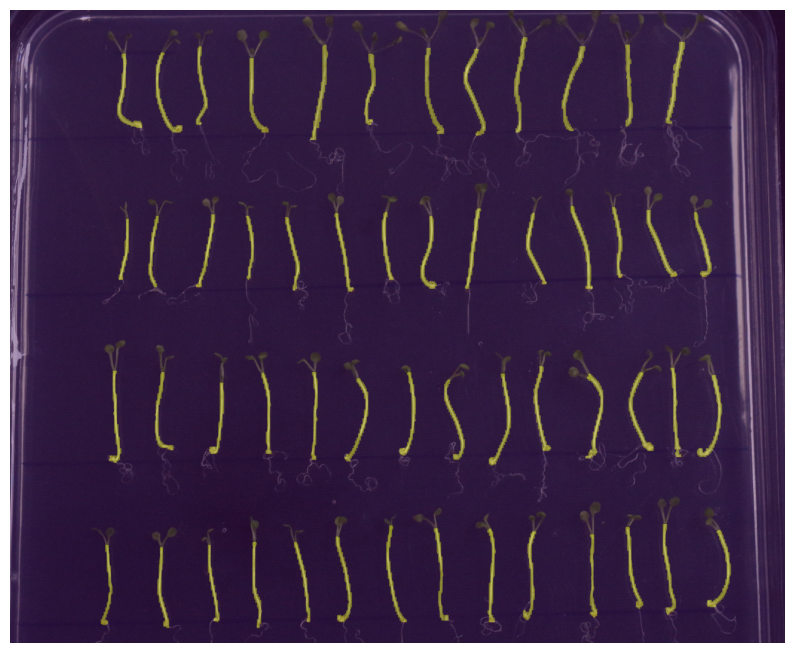

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.imshow(image)
plt.imshow(clean_mask, alpha=0.4, )
plt.axis("off")
plt.show()




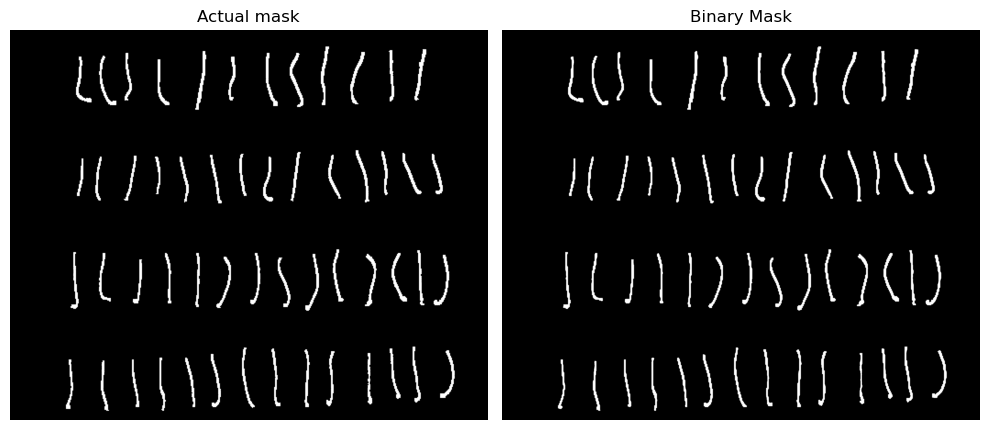

In [8]:
import matplotlib.pyplot as plt
kernel = np.ones((3,3), np.uint8)

clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)
actualmask = cv2.morphologyEx(actualmask, cv2.MORPH_CLOSE, kernel)
plt.figure(figsize=(10,8))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(actualmask, cmap="gray", vmin=0, vmax=1)
plt.title("Actual mask")
plt.axis("off")

# Binary mask
plt.subplot(1, 2, 2)
plt.imshow(clean_mask, cmap="gray", vmin=0, vmax=1)
plt.title("Binary Mask")
plt.axis("off")



plt.tight_layout()
plt.show()



Colour coded difference map

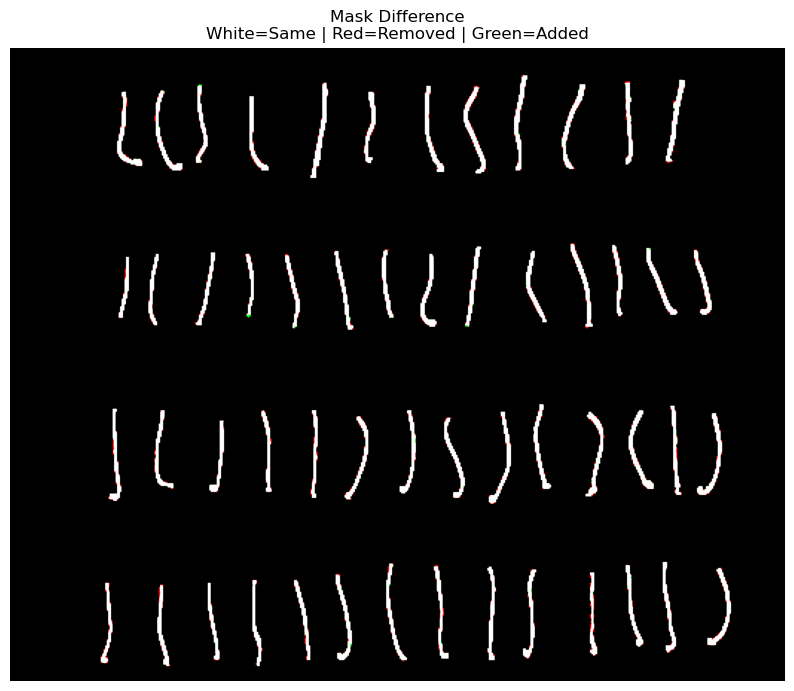

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def show_mask_difference(gt_mask, clean_mask):
    """
    gt_mask: original / binary mask
    clean_mask: filtered mask
    """

    gt = (gt_mask > 0).astype(np.uint8)
    pred = (clean_mask > 0).astype(np.uint8)

   
    diff = np.zeros((gt.shape[0], gt.shape[1], 3), dtype=np.uint8)

    # True Positive → White
    diff[(gt == 1) & (pred == 1)] = [255, 255, 255]

    # Removed pixels (present before, gone now) → Red
    diff[(gt == 1) & (pred == 0)] = [255, 0, 0]

    # Newly added (shouldn't happen ideally) → Green
    diff[(gt == 0) & (pred == 1)] = [0, 255, 0]

    plt.figure(figsize=(10,10))
    plt.imshow(diff)
    plt.title("Mask Difference\nWhite=Same | Red=Removed | Green=Added")
    plt.axis("off")
    plt.show()

show_mask_difference(actualmask, clean_mask)

Skeletonization and pixel length calculation

In [ ]:
import numpy as np
from scipy.spatial import KDTree
from scipy.sparse import dok_matrix
from scipy.sparse.csgraph import dijkstra
import cv2
from skimage.morphology import skeletonize

def compute_main_backbone_length(skeleton):
    coords = np.column_stack(np.where(skeleton))
    n = len(coords)
    
    if n == 0:
        return 0.0
    if n == 1:
        return 1.0
        
    # Find adjacent pixels (distance < 1.5 grabs orthogonal and diagonal neighbors)
    tree = KDTree(coords)
    pairs = tree.query_pairs(r=1.5)
    
    # Build a sparse adjacency graph
    graph = dok_matrix((n, n), dtype=np.float32)
    for i, j in pairs:
        dist = np.linalg.norm(coords[i] - coords[j])
        graph[i, j] = dist
        graph[j, i] = dist
        
    graph = graph.tocsr()
    
    # Find endpoints (pixels with exactly 1 connection in the skeleton)
    degrees = graph.getnnz(axis=1)
    endpoints = np.where(degrees == 1)[0]
    
    # Fallback if it's a closed loop (no endpoints)
    if len(endpoints) == 0:
        endpoints = [0]
        
    # Use Dijkstra's algorithm to find the shortest paths from all endpoints to all other nodes
    dist_matrix = dijkstra(csgraph=graph, directed=False, indices=endpoints)
    
    # Replace infinity (disconnected components) with 0
    dist_matrix[dist_matrix == np.inf] = 0
    
    # The true length is the absolute longest path between any two endpoints
    main_length = np.max(dist_matrix)
    
    return main_length

def compute_skeleton_lengths(clean_mask, min_size=50, return_skeleton_map=False):
    clean_mask = (clean_mask > 0).astype(np.uint8)

    # 1. Gaussian Blur for Boundary Smoothing (Anti-Zigzag)
    mask_float = clean_mask.astype(np.float32)
    blurred = cv2.GaussianBlur(mask_float, (9, 9), 3.0) 
    clean_mask = (blurred > 0.5).astype(np.uint8)

    # 2. Use connectedComponentsWithStats to get labels, stats (area), and centroids instantly
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(clean_mask)

    lengths = []
    valid_centroids =[]
    skeleton_map = np.zeros_like(clean_mask, dtype=np.uint8)

    for label_id in range(1, num_labels): # Skip 0 (background)
        
        # Filter noise using pre-computed area stats (Much faster than np.sum)
        area = stats[label_id, cv2.CC_STAT_AREA]
        if area < min_size:
            continue

        component = (labels == label_id).astype(np.uint8)

        # Create skeleton
        skeleton = skeletonize(component)

        # Get the longest path backbone length (using the function from the previous answer)
        pixel_length = compute_main_backbone_length(skeleton)
        
        # Store the results
        lengths.append(pixel_length)
        valid_centroids.append(centroids[label_id]) # OpenCV returns (x, y) coordinates

        skeleton_map[skeleton] = 1

    lengths = np.array(lengths)
    valid_centroids = np.array(valid_centroids)

    if return_skeleton_map:
        return lengths, skeleton_map, valid_centroids

    return lengths, valid_centroids

In [10]:
from scipy.spatial.distance import cdist
lengths1, skel_map1, centroids1 = compute_skeleton_lengths(clean_mask, return_skeleton_map=True)
lengths2, skel_map2, centroids2 = compute_skeleton_lengths(actualmask, return_skeleton_map=True)

dist_matrix = cdist(centroids1, centroids2)

matched_indices = dist_matrix.argmin(axis=1)

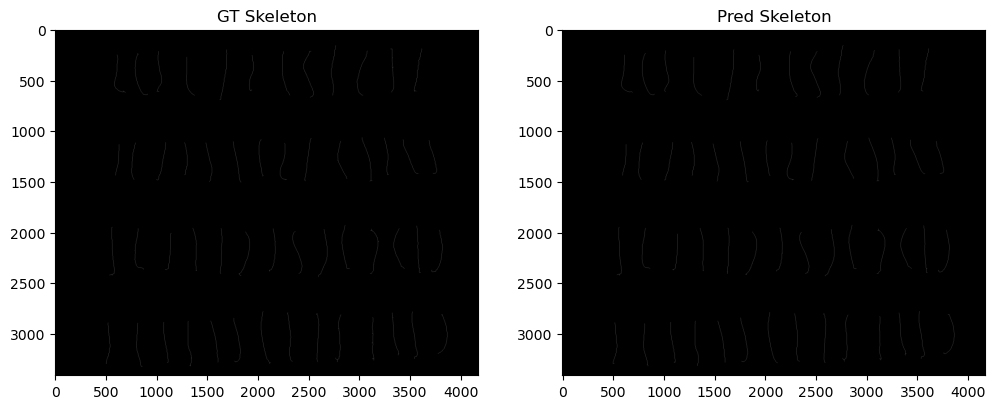

In [11]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(skel_map2, cmap='gray')
plt.title("GT Skeleton")

plt.subplot(1,2,2)
plt.imshow(skel_map1, cmap='gray')
plt.title("Pred Skeleton")

plt.show()

Draw a line over the actual scale present on top left of the image which will act as a reference for calculating actual length.

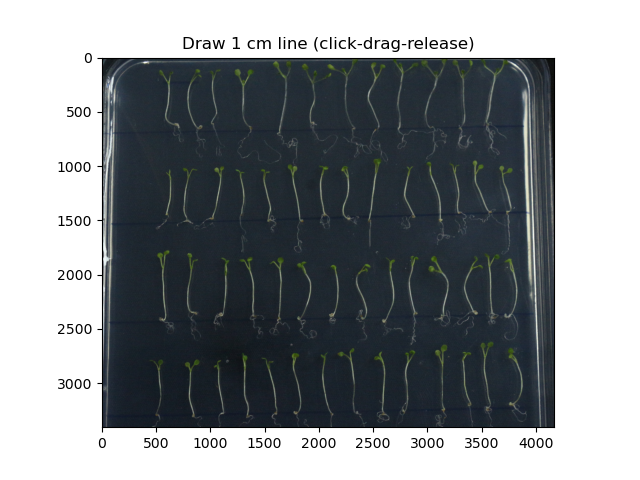

In [12]:
%matplotlib widget

import matplotlib.pyplot as plt
import cv2
import numpy as np



fig, ax = plt.subplots()
ax.imshow(image)
ax.set_title("Draw 1 cm line (click-drag-release)")

start_point = None
line = None
PIXEL_TO_MM = None  # global calibration

def on_press(event):
    global start_point, line

    if event.xdata is None or event.ydata is None:
        return

    start_point = (event.xdata, event.ydata)

    if line is not None:
        line.remove()

def on_motion(event):
    global line

    if start_point is None or event.xdata is None or event.ydata is None:
        return

    x0, y0 = start_point
    x1, y1 = event.xdata, event.ydata

    if line is not None:
        line.remove()

    line, = ax.plot([x0, x1], [y0, y1], 'g-', linewidth=2)
    fig.canvas.draw_idle()

def on_release(event):
    global start_point, PIXEL_TO_MM

    if start_point is None or event.xdata is None or event.ydata is None:
        return

    x0, y0 = start_point
    x1, y1 = event.xdata, event.ydata

    pixel_dist = np.sqrt((x1 - x0)**2 + (y1 - y0)**2)
    print("Pixel distance:", pixel_dist)

    PIXEL_TO_MM = 10 / pixel_dist
    print("PIXEL_TO_MM (mm per pixel):", PIXEL_TO_MM)

    start_point = None

# Connect events
fig.canvas.mpl_connect('button_press_event', on_press)
fig.canvas.mpl_connect('motion_notify_event', on_motion)
fig.canvas.mpl_connect('button_release_event', on_release)

plt.show()

Convert pixel count to actual physical length .

In [14]:
for i, j in enumerate(matched_indices):
    pred_mm = lengths1[i] * PIXEL_TO_MM
    actual_mm = lengths2[j] * PIXEL_TO_MM
    diff = pred_mm - actual_mm

    print(f"Sapling {i+1}: Pred = {pred_mm:.2f} mm | "
          f"Actual = {actual_mm:.2f} mm | Diff = {diff:.2f} mm")


Sapling 1: Pred = 19.62 mm | Actual = 19.68 mm | Diff = -0.06 mm
Sapling 2: Pred = 17.56 mm | Actual = 18.06 mm | Diff = -0.50 mm
Sapling 3: Pred = 16.62 mm | Actual = 17.25 mm | Diff = -0.62 mm
Sapling 4: Pred = 19.97 mm | Actual = 19.92 mm | Diff = 0.05 mm
Sapling 5: Pred = 16.80 mm | Actual = 16.61 mm | Diff = 0.19 mm
Sapling 6: Pred = 18.91 mm | Actual = 19.58 mm | Diff = -0.67 mm
Sapling 7: Pred = 18.54 mm | Actual = 17.49 mm | Diff = 1.04 mm
Sapling 8: Pred = 20.31 mm | Actual = 21.06 mm | Diff = -0.75 mm
Sapling 9: Pred = 18.68 mm | Actual = 18.75 mm | Diff = -0.07 mm
Sapling 10: Pred = 17.44 mm | Actual = 17.60 mm | Diff = -0.16 mm
Sapling 11: Pred = 14.72 mm | Actual = 14.69 mm | Diff = 0.03 mm
Sapling 12: Pred = 15.68 mm | Actual = 15.90 mm | Diff = -0.22 mm
Sapling 13: Pred = 17.75 mm | Actual = 17.83 mm | Diff = -0.08 mm
Sapling 14: Pred = 14.62 mm | Actual = 14.64 mm | Diff = -0.02 mm
Sapling 15: Pred = 16.64 mm | Actual = 16.86 mm | Diff = -0.22 mm
Sapling 16: Pred = 14.9

In [ ]:
def save_results(lengths1, lengths2, PIXEL_TO_MM, image_name, file_path="results.csv"):
    import pandas as pd
    import numpy as np
    import os

    lengths1_mm = lengths1 * PIXEL_TO_MM
    lengths2_mm = lengths2 * PIXEL_TO_MM

    min_len = min(len(lengths1_mm), len(lengths2_mm))

    data = []
    for i in range(min_len):
        pred = lengths1_mm[i]
        actual = lengths2_mm[i]
        diff = pred - actual

        data.append({
            "Image": image_name,
            "Sapling_ID": i + 1,
            "Predicted_mm": round(pred, 2),
            "Actual_mm": round(actual, 2),
            "Difference_mm": round(diff, 2)
        })

    df = pd.DataFrame(data)

    # Append if file exists
    if os.path.exists(file_path):
        existing_df = pd.read_csv(file_path)
        df = pd.concat([existing_df, df], ignore_index=True)

    # Save
    df.to_csv(file_path, index=False)
    print(f"Saved {len(df)} total rows to {file_path}")

save_results(lengths1, lengths2, PIXEL_TO_MM, "n1.jpg")

Saved 227 total rows to results.csv


Plot scatter plot.

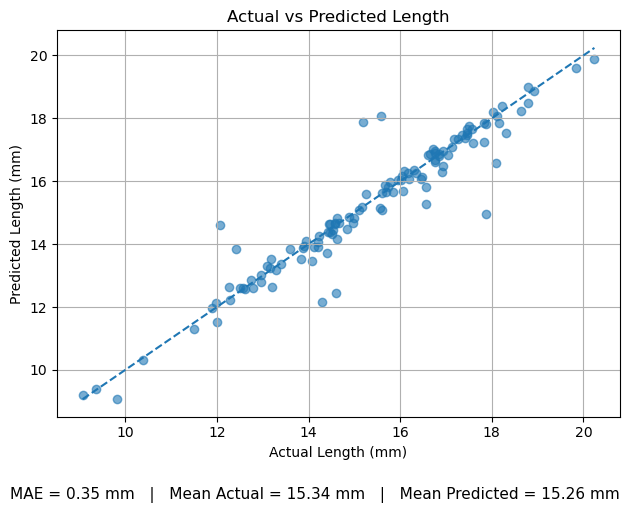

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
df = pd.read_csv("results1.csv")

# Metrics
mae = np.mean(np.abs(df["Actual_mm"] - df["Predicted_mm"]))
mean_actual = df["Actual_mm"].mean()
mean_pred = df["Predicted_mm"].mean()

# Plot
plt.figure()

plt.scatter(df["Actual_mm"], df["Predicted_mm"], alpha=0.6)

# Perfect prediction line
min_val = min(df["Actual_mm"].min(), df["Predicted_mm"].min())
max_val = max(df["Actual_mm"].max(), df["Predicted_mm"].max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')

# Labels and title
plt.xlabel("Actual Length (mm)")
plt.ylabel("Predicted Length (mm)")
plt.title("Actual vs Predicted Length")

plt.grid()

# Add text BELOW the plot
plt.figtext(
    0.5, -0.05,
    f"MAE = {mae:.2f} mm   |   Mean Actual = {mean_actual:.2f} mm   |   Mean Predicted = {mean_pred:.2f} mm",
    ha="center",
    fontsize=11
)

# Adjust layout so text is visible
plt.tight_layout()

plt.show()